# 모의고사 4회 풀이

자료 이해 → 고정 분석 조건 → 문항별 풀이 근거 → 실행 코드 → 실제 결과의 순서로 읽으십시오. 전체를 위에서 아래로 실행합니다. 변수의 산업적 의미는 각 절의 사전을 따르며, 공식 정답이나 실제 현장 성능을 뜻하지 않습니다.

실제 결과를 모은 [해설](해설.md)과 [자료 사전](자료안내.md)을 함께 사용하십시오.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from IPython.display import display

# repository root 또는 회차 폴더에서 탐색; 경로를 하드코딩하지 않음.
ROOT = next(
    p
    for p in [Path.cwd()] + list(Path.cwd().parents)
    if (p / "기출문제/공통/reconstruction.py").exists()
)
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "기출문제/공통"))
from reconstruction import *
from matplotlib import font_manager

font_path = ROOT / "기출문제/공통/NanumGothic-Regular.ttf"
font_manager.fontManager.addfont(str(font_path))
plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False
HERE = ROOT / "기출문제" / "모의고사/4회"
DATA = HERE / "data"
OUT = HERE / "실행결과"
OUT.mkdir(exist_ok=True)


def load(name):
    return pd.read_csv(DATA / name)


print("데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님")

# 상황형 답안 기록 초기화
_SCENARIO_ROOT = next(
    p
    for p in [Path.cwd()] + list(Path.cwd().parents)
    if (p / "기출문제/공통/scenario_inference.py").is_file()
)
sys.path.insert(0, str(_SCENARIO_ROOT / "기출문제/공통"))
from scenario_inference import (
    reset_reports,
    set_question,
    report_test,
    report_anova,
    report_correlations,
    report_adf,
    report_residuals,
    report_regression_diagnostics,
)

reset_reports(OUT)

데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님


## 1. 다음날 강수 예측

**상황을 이해하기**

관측된 날의 기상 정보로 다음날 비가 올지를 예측합니다.

**관측 단위와 판단 목적**

한 행은 날짜·지역별 기상 관측입니다. 지문의 무작위 분할은 학습용 조건이며 실제 미래 예보의 시간 분할과 구분합니다. 지문에서 요구한 비교·예측·요약의 결과와 불확실성을 상황에 맞게 보고합니다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `weatherAUS.csv / Date` | 관측 날짜 |
| `weatherAUS.csv / Location` | 관측 지역 |
| `weatherAUS.csv / Rainfall` | 당일 강우량 지표 |
| `weatherAUS.csv / Humidity` | 습도 지표 |
| `weatherAUS.csv / Cloud9am` | 오전 구름량 지표 |
| `weatherAUS.csv / RainTomorrow` | 다음날 비 여부 Yes/No |

**고정 분석 조건**

기상팀은 RainTomorrow를 예측하려 한다. weatherAUS의 결측이 10,000개 이상인 열을 제외하고 나머지 완전 관측 행을 사용하는 연습 조건이다. 같은 7:3 분할·시드 6789를 이 대문항에서 재사용한다.


### 1-1

**문제**

열별 결측 수로 제외 대상을 결정하고 남은 결측 행을 제거하시오. Date를 날짜형으로 변환하고 7:3 자료를 구성하시오. 이 조건부 표본과 랜덤 분할이 실제 미래 강수 예측에 주는 한계를 설명하시오.

**풀이 근거와 읽는 순서**

고정 열명 삭제 대신 결측 개수 조건을 검사합니다.

날짜 변환을 확인하고 Python 시드 6789로 7:3 분할합니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [2]:
set_question("1-1")
weather = load("weatherAUS.csv")
print(weather.describe(include="all"))
missing = weather.isna().sum()
dropped = missing[missing >= 10000].index.tolist()
weather = weather.drop(columns=dropped).dropna().copy()
weather["Date"] = pd.to_datetime(weather.Date)
print("제외 열:", dropped, "남은 행:", len(weather))
train, test = train_test_split(
    np.arange(len(weather)),
    test_size=0.3,
    random_state=6789,
    stratify=weather.RainTomorrow,
)
print(len(train), len(test))

              Date Location  ...    Cloud9am  RainTomorrow
count        10520    10520  ...  510.000000         10520
unique       10520        3  ...         NaN             2
top     1995-01-01        A  ...         NaN           Yes
freq             1     3558  ...         NaN          5633
mean           NaN      NaN  ...    4.393580           NaN
std            NaN      NaN  ...    2.652514           NaN
min            NaN      NaN  ...    0.010161           NaN
25%            NaN      NaN  ...    2.022702           NaN
50%            NaN      NaN  ...    4.328582           NaN
75%            NaN      NaN  ...    6.770503           NaN
max            NaN      NaN  ...    8.966937           NaN

[11 rows x 6 columns]
제외 열: ['Cloud9am'] 남은 행: 10520
7364 3156


### 1-2

**문제**

다른 원리의 분류 모형 3개 이상을 같은 학습 자료에 적합하고 시험 예측값을 모형별 CSV로 제출하시오. 전처리와 비교 조건을 명시하시오.

**풀이 근거와 읽는 순서**

세 모델에서 같은 holdout을 사용해 예측 CSV를 각각 출력합니다.

다음날 강수 운영에는 미래 시간 분할로 추가 검증해야 합니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

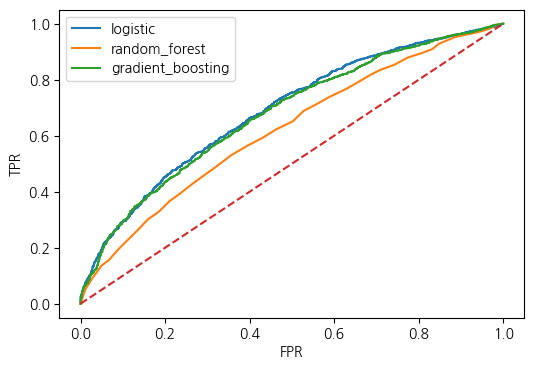

               model  accuracy  f1_weighted   ROC_AUC
0           logistic  0.633080     0.631101  0.686744
1      random_forest  0.583016     0.582571  0.620399
2  gradient_boosting  0.628961     0.627132  0.677542


In [3]:
set_question("1-2")
weather_scores, weather_models, train, test = classify(
    weather, "RainTomorrow", [c for c in weather if c != "RainTomorrow"], OUT, seed=6789
)

### 1-3(보충)

**문제**

같은 시험 자료의 정확도와 양성 확률 ROC-AUC를 비교하시오. 모형별 장단점과 시간순 운영 검증이 추가로 필요한 이유를 설명하시오.

**풀이 근거와 읽는 순서**

원본 질문 셀에는 없지만 첨부 code 29~46의 성과 분석을 보충문항으로 구분했습니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [4]:
set_question("1-3(보충)")
print(weather_scores)
print("시간 순 운영에서는 랜덤분할 지표가 낙관적일 수 있습니다.")

               model  accuracy  f1_weighted   ROC_AUC
0           logistic  0.633080     0.631101  0.686744
1      random_forest  0.583016     0.582571  0.620399
2  gradient_boosting  0.628961     0.627132  0.677542
시간 순 운영에서는 랜덤분할 지표가 낙관적일 수 있습니다.


## 2. 마케팅과 매출

**상황을 이해하기**

사업장별 광고 투입과 매출의 관계를 살펴 광고 운영을 검토합니다.

**관측 단위와 판단 목적**

한 행은 독립 사업장입니다. marketing_total은 개별 채널 합이므로 모두 넣으면 선형 중복이 생깁니다. 지문에서 요구한 비교·예측·요약의 결과와 불확실성을 상황에 맞게 보고합니다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `bike_marketing.csv / pop_density` | 사업장 지역의 인구밀도 범주 |
| `bike_marketing.csv / google_adwords` | 검색 광고비 지표 |
| `bike_marketing.csv / facebook` | 사회관계망 광고비 지표 |
| `bike_marketing.csv / twitter` | 단문 게시 채널 광고비 지표 |
| `bike_marketing.csv / marketing_total` | 세 광고 채널 비용의 합 |
| `bike_marketing.csv / employees` | 직원 수 |
| `bike_marketing.csv / revenues` | 매출 지표 |

**고정 분석 조건**

마케팅팀은 지역 인구밀집 범주와 revenues의 관계 및 채널별 광고 기여를 설명하려 한다. 독립 사업장 표본이며 범주 평균 비교에는 정규 오차·등분산을 작업 가정으로 둔다. marketing_total은 세 채널 비용의 합이다.


### 2-1

**문제**

pop_density를 범주로 취급하고 범주별 평균 매출이 같은지 유의수준 5%에서 판단하시오. 검정 선택·가설·통계량·p-value·기각 여부를 제시하고 필요하면 후속 집단 비교를 수행하시오.

**풀이 근거와 읽는 순서**

독립 집단의 수치 반응을 설명하는 요인 모형을 선택한다.

한 요인이면 H0: 모든 집단 평균이 같다, H1: 적어도 하나 다르다.

두 요인이면 주효과와 상호작용의 가설·p값을 각각 구분한다.

정규 오차·등분산은 작업 가정이며 적합성을 검토한다.

**계산·해석 상세**

H0: 인구밀집 범주별 평균 매출이 같습니다.

p>=.05면 귀무가설을 기각하지 못합니다.

원문 “대립가설 기각” 표현을 바로잡습니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [5]:
set_question("2-1")
bike = load("bike_marketing.csv")
bike["pop_density"] = bike.pop_density.astype("category")
anova(bike, "revenues", "pop_density")

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
_aov_model = anova(bike, "revenues", "pop_density")
report_anova(_aov_model, "revenues", ["pop_density"])

                      sum_sq     df        F    PR(>F)
C(pop_density)  3.002313e+04    2.0  0.55108  0.577359
Residual        4.603605e+06  169.0      NaN       NaN
유의하면 적어도 한 평균/효과가 다릅니다. 모든 쌍이 다르다는 뜻은 아닙니다.
등분산 Levene: LeveneResult(statistic=np.float64(0.10245579292560225), pvalue=np.float64(0.9026740722440879))
ANOVA 유의하지 않아 사후검정을 주 결론으로 수행하지 않습니다.
합성 자료의 예시 추론. 정규성·등분산·독립성 및 표본 설계를 실제 자료에서 재검증하세요.
                      sum_sq     df        F    PR(>F)
C(pop_density)  3.002313e+04    2.0  0.55108  0.577359
Residual        4.603605e+06  169.0      NaN       NaN
유의하면 적어도 한 평균/효과가 다릅니다. 모든 쌍이 다르다는 뜻은 아닙니다.
등분산 Levene: LeveneResult(statistic=np.float64(0.10245579292560225), pvalue=np.float64(0.9026740722440879))
ANOVA 유의하지 않아 사후검정을 주 결론으로 수행하지 않습니다.
합성 자료의 예시 추론. 정규성·등분산·독립성 및 표본 설계를 실제 자료에서 재검증하세요.
{
  "question": "2-1",
  "method": "독립 집단 요인 모형의 Type II F 검정: pop_density 주효과",
  "H0": "pop_density 주효과가 없다",
  "H1": "pop_density 주효과가 있다",
  "statistic": 0.5510799898785986,
  "p_value":

### 2-2

**문제**

google_adwords·facebook·twitter·marketing_total·employees를 후보로 매출 설명 모형을 구성하시오. 빈 모형에서 변수를 추가하는 선택 기준을 명시하고 합계 변수의 공선성을 처리하시오.

**풀이 근거와 읽는 순서**

후보 추가로 AIC가 엄격하게 낮아질 때 전진합니다.

설계행렬 rank가 부족한 조합은 선택하지 않습니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [6]:
set_question("2-2")
bike_model = select_ols(
    bike,
    "revenues",
    ["google_adwords", "facebook", "twitter", "marketing_total", "employees"],
    "forward",
)

선택 변수: ['google_adwords', 'employees', 'facebook']
   step                           features          AIC
0     1                     google_adwords  2157.874030
1     2           google_adwords,employees  1953.590440
2     3  google_adwords,employees,facebook  1908.456346
                            OLS Regression Results                            
Dep. Variable:               revenues   R-squared:                       0.863
Model:                            OLS   Adj. R-squared:                  0.861
Method:                 Least Squares   F-statistic:                     353.7
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           2.43e-72
Time:                        11:26:56   Log-Likelihood:                -950.23
No. Observations:                 172   AIC:                             1908.
Df Residuals:                     168   BIC:                             1921.
Df Model:                           3                                         
Covariance Typ

### 2-3

**문제**

선택한 모형의 잔차를 이용해 오차 분포와 분산의 적절성을 점검하시오. 적절한 진단 방법과 각 가설·통계량·p-value·기각 여부 및 결과 해석의 한계를 제시하시오.

**풀이 근거와 읽는 순서**

잔차의 정규성은 Shapiro-Wilk, 등분산은 Breusch-Pagan으로 점검한다.

H0의 내용이 다르므로 p값·기각 여부를 따로 보고한다.

선택된 회귀식의 진단은 확증 인과 검정이 아니다.

**계산·해석 상세**

정규성은 원 y가 아니라 잔차를 진단합니다.

DW가 2에 가깝다는 사실만으로 관측 독립성을 입증하지 않습니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

{'Shapiro_p': np.float64(0.6601921298427909), 'Breusch_Pagan_p': np.float64(0.8851551310809335), 'Durbin_Watson': np.float64(1.946042663736713)}
p>=0.05는 귀무가설을 기각하지 못함입니다. 독립성은 관측 설계·시간 순서도 확인합니다.


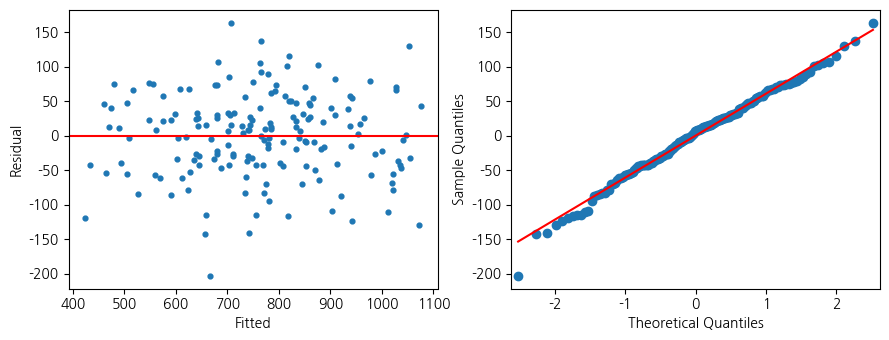

{
  "question": "2-3",
  "method": "Shapiro-Wilk 잔차 진단",
  "H0": "잔차 분포가 정규이다",
  "H1": "잔차 분포가 정규가 아니다",
  "statistic": 0.9936244267804669,
  "p_value": 0.6601921298427909,
  "alpha": 0.05,
  "reject_H0": false,
  "assumptions": "선택된 모형의 잔차를 이용한 탐색 진단이며 선택 후 추론의 한계가 있다.",
  "conclusion": "귀무가설을 기각하지 못한다. 잔차 분포가 정규에서 벗어난다는 통계적 근거가 충분하지 않다. 귀무가설의 참을 입증한 것은 아니다."
}
{
  "question": "2-3",
  "method": "Breusch-Pagan 잔차 진단",
  "H0": "오차 분산이 일정하다",
  "H1": "오차 분산이 일정하지 않다",
  "statistic": 0.648887070077262,
  "p_value": 0.8851551310809335,
  "alpha": 0.05,
  "reject_H0": false,
  "assumptions": "독립 관측과 지정된 분산 설명 구조에 의존하는 점근적 진단이다.",
  "conclusion": "귀무가설을 기각하지 못한다. 잔차에 이분산이 존재한다는 통계적 근거가 충분하지 않다. 귀무가설의 참을 입증한 것은 아니다.",
  "df": 3
}


In [7]:
set_question("2-3")
residual_diagnostics(bike_model)

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
report_regression_diagnostics(bike_model)

## 3. 여행 게시글 관심 단어

**상황을 이해하기**

문서에서 관심 단어의 빈도와 날짜별 관심을 요약합니다.

**관측 단위와 판단 목적**

한 행은 문서 한 건입니다. 품사는 제공된 학습 사전의 표시에 한정됩니다. 지문에서 요구한 비교·예측·요약의 결과와 불확실성을 상황에 맞게 보고합니다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `instagram.csv / date` | 문서 작성 날짜 |
| `instagram.csv / text` | 분석할 문서 내용 |
| `lexicon.csv / word` | 학습용 품사 사전에 등록된 단어 |
| `lexicon.csv / pos` | Noun=명사, Adjective=형용사 |

**고정 분석 조건**

별도의 합성 여행 게시글과 품사 사전으로 자주 언급되는 주제를 요약하려 한다. 태교여행은 한 명사 단위로 등록된 표현이다.


### 3-1

**문제**

문서 경계를 유지하면서 숫자·특수문자를 정제하시오. 원문과 정제 결과를 함께 확인하시오.

**풀이 근거와 읽는 순서**

텍스트 정제 뒤 원 문서와 대응을 유지합니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [8]:
set_question("3-1")
instagram = load("instagram.csv")
lexicon = load("lexicon.csv")
instagram["clean"] = instagram.text.map(clean_text)
print(instagram.head())

         date                            text                    clean
0  2026-01-15      호텔 맛 공구 영화 호텔 맛 즐겁다 123 !@      호텔 맛 공구 영화 호텔 맛 즐겁다
1  2026-01-16     호텔 행복 행복 맛 호텔 행복 즐겁다 123 !@     호텔 행복 행복 맛 호텔 행복 즐겁다
2  2026-01-17      배송 가족 여행 영화 호텔 맛 좋다 123 !@      배송 가족 여행 영화 호텔 맛 좋다
3  2026-01-18  영화 태교여행 여행 호텔 여행 가족 빠르다 123 !@  영화 태교여행 여행 호텔 여행 가족 빠르다
4  2026-01-19    학교 호텔 학교 학교 학교 행복 빠르다 123 !@    학교 호텔 학교 학교 학교 행복 빠르다


### 3-2

**문제**

태교여행이 명사 사전에 등록되었는지 검증하고 명사 빈도 상위 10개를 시각화하시오. 사전 구성에 따라 빈도가 달라지는 이유를 설명하시오.

**풀이 근거와 읽는 순서**

태교여행은 합성 사전에 하나의 Noun 단위로 등록해 분리하지 않습니다.

실제 원문은 별도 형태소 사전 등록이 필요합니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

   word  count
0    가족     41
1    여행     39
2    행복     38
3    공구     37
4    영화     36
5     맛     35
6  태교여행     34
7    학교     34
8    호텔     33
9    배송     33


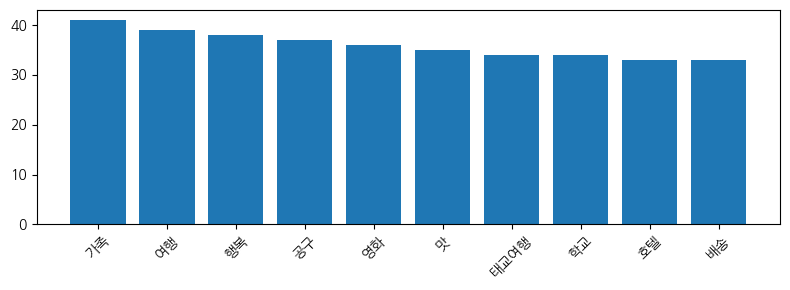

In [9]:
set_question("3-2")
assert "태교여행" in lexicon.word.tolist()
word_plot(lexical_pos(instagram.text, lexicon), 10)